# Visualizing Patch Tokenization Strategies

Compares 16x16 square patches vs vertical frame patches (128xW) on a single mel spectrogram.
Shows why vertical frames are a better fit for spectrograms: each token sees the full frequency band.

In [6]:
import sys

sys.path.insert(0, "../src")

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import soundfile as sf
import torch
from matplotlib.colors import to_rgba

from birdset_benchmark.datasets import load_birdset_dataset
from birdset_benchmark.preprocessing.mel_spectrogram import MelSpectrogramTransform

In [ ]:
# Load one sample from HSN
dataset = load_birdset_dataset("HSN", split="test_5s", subset_size=10)
sample = dataset[0]

# Audio is stored as a file path, not decoded bytes
audio_path = sample["audio"]["path"] or sample["filepath"]
audio_data, sr = sf.read(audio_path)
if audio_data.ndim > 1:
    audio_data = audio_data.mean(axis=1)  # stereo -> mono
audio = torch.tensor(audio_data, dtype=torch.float32)
print(f"Audio: {audio.shape[0] / sr:.1f}s @ {sr}Hz, from {audio_path.split('/')[-1]}")

Audio: 5.0s @ 32000Hz, from HSN_100_20150712_091105_405_410.ogg


In [8]:
# Generate mel spectrogram (128 x 500)
mel_transform = MelSpectrogramTransform(sample_rate=sr)
mel = mel_transform(audio)  # (1, 128, 500)
spec = mel.squeeze(0).numpy()  # (128, 500)
print(f"Spectrogram shape: {spec.shape}")

Spectrogram shape: (128, 500)


In [19]:
def draw_patch_grid(ax, spec, patch_h, patch_w, title, highlight_patches=None):
    """Draw spectrogram with patch grid overlay."""
    H, W = spec.shape
    ax.imshow(spec, aspect="auto", origin="lower", cmap="magma", extent=[0, W, 0, H])

    # Draw grid lines
    for x in range(0, W + 1, patch_w):
        ax.axvline(x, color="white", linewidth=0.3, alpha=0.5)
    for y in range(0, H + 1, patch_h):
        ax.axhline(y, color="white", linewidth=0.3, alpha=0.5)

    # Highlight a few patches
    if highlight_patches:
        colors = ["#00ff88", "#ff6644", "#44aaff"]
        for i, (py, px) in enumerate(highlight_patches):
            rect = mpatches.FancyBboxPatch(
                (px * patch_w, py * patch_h),
                patch_w,
                patch_h,
                linewidth=2,
                edgecolor=colors[i % len(colors)],
                facecolor=to_rgba(colors[i % len(colors)], 0.2),
                boxstyle="round,pad=0",
            )
            ax.add_patch(rect)

    n_freq = H // patch_h
    n_time = W // patch_w
    ax.set_title(f"{title}\n{n_freq}x{n_time} = {n_freq * n_time} tokens", fontsize=12)
    ax.set_xlabel("Time frames")
    ax.set_ylabel("Mel bins")

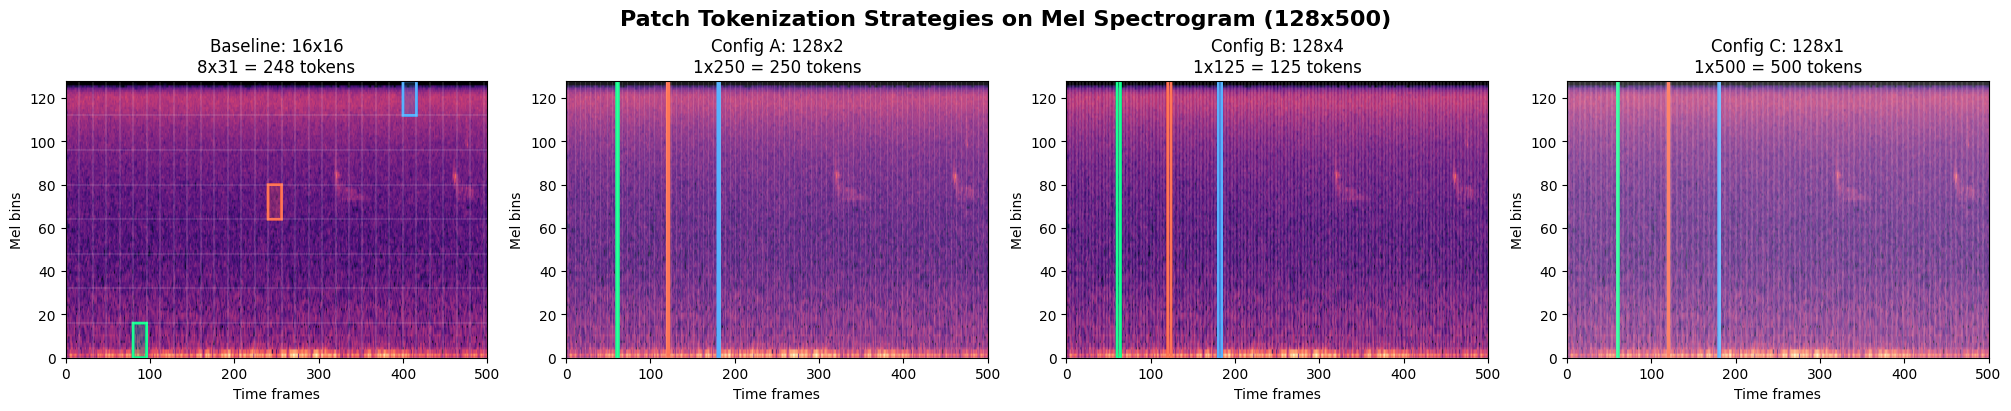

In [22]:
configs = [
    ("Baseline: 16x16", 16, 16, [(0, 5), (4, 15), (7, 25)]),
    ("Config A: 128x2", 128, 2, [(0, 30), (0, 60), (0, 90)]),
    ("Config B: 128x4", 128, 4, [(0, 15), (0, 30), (0, 45)]),
    ("Config C: 128x1", 128, 1, [(0, 60), (0, 120), (0, 180)]),
]

fig, axes = plt.subplots(1, 4, figsize=(20, 4), constrained_layout=True)

for ax, (title, ph, pw, highlights) in zip(axes, configs, strict=False):
    draw_patch_grid(ax, spec, ph, pw, title, highlights)

fig.suptitle(
    "Patch Tokenization Strategies on Mel Spectrogram (128x500)",
    fontsize=16,
    fontweight="bold",
)
plt.savefig("../artifacts/tokenization_comparison.png", dpi=100, bbox_inches="tight")
plt.show()

In [21]:
# Summary table
print(
    f"{'Config':<20} {'Patch':>10} {'Tokens':>8} {'Freq Res':>10} {'Time Res':>10} {'Embed In':>10}"
)
print("-" * 72)
for name, ph, pw, _ in configs:
    n_freq = 128 // ph
    n_time = 500 // pw
    tokens = n_freq * n_time
    freq_res = f"{ph} bins" if ph < 128 else "full band"
    time_res = f"{pw * 10}ms"
    embed_in = ph * pw
    print(
        f"{name:<20} {ph}x{pw:>3}     {tokens:>5}   {freq_res:>10}   {time_res:>10}   {embed_in:>10}"
    )

Config                    Patch   Tokens   Freq Res   Time Res   Embed In
------------------------------------------------------------------------
Baseline: 16x16      16x 16       248      16 bins        160ms          256
Config A: 128x2      128x  2       250    full band         20ms          256
Config B: 128x4      128x  4       125    full band         40ms          512
Config C: 128x1      128x  1       500    full band         10ms          128
